# Efficient and Fault-Resilient GNNs for Illicit Bitcoin Transaction Detection (Elliptic)

**Version 2: multi-seed evaluation with non-graph baselines and validation-tuned thresholds**


1. **Five training seeds** for every neural model. All results are reported as mean ± SD, and comparisons are paired by seed.
2. **Non-graph baselines** to test whether the graph helps: logistic regression, random forest and an MLP. The MLP uses the same training loop as the GNNs but ignores the edges.
3. **Decision threshold tuned on the validation set** (it maximises illicit F1) and then applied unchanged to the test set. F1 at 0.5 is still reported for reference. AUPRC is the primary metric.
4. **Honest description of compression:**
   - Quantisation is simulated, weight-only, post-training, symmetric and per-tensor. Weights are rounded to INT8/INT4 and then stored back in FP32.
   - Biases, BatchNorm parameters and activations remain FP32.
   - No real speed-up or memory saving is measured.
5. **Fault sweep:** 5 trained models × 3 fault seeds per cell, reported as a table with mean ± SD.
6. **Data sanity checks:** dataset size, label counts, edges that cross time steps, and the change in illicit share between splits.
7. **Per-time-step test analysis**, because the illicit share changes strongly over time in Elliptic.
8. **Saved outputs** (`results/` folder) and a printed **RESULTS SUMMARY** block to copy back.



**Cell 1: Install PyTorch Geometric and KaggleHub**

In [1]:
!pip install -q torch_geometric kagglehub

**Cell 2: Configuration, reproducibility and device**



In [2]:
import os, time, copy, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric
import sklearn

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200, "display.max_columns", 30)

CONFIG = dict(
    seeds=[0, 1, 2, 3, 4],            # training seeds for every model
    fault_seeds_per_model=3,          # fault-injection repeats per trained model
    hidden=128, dropout=0.3, epochs=120, eval_every=5,
    lr={"MLP": 0.005, "GCN": 0.005, "GIN": 0.003}, weight_decay=5e-4,
    train_steps=(1, 28), val_steps=(29, 34), test_steps=(35, 49),
    bits=[8, 4], sparsities=[0.5, 0.8],
    fault_rates=[0.0, 0.001, 0.005, 0.01, 0.02, 0.05],
    rf_trees=100, rf_max_features=50,
    data_dir=None,                    # optional: a folder that contains the three Elliptic CSV files
    out_dir="results",
)
OUT = Path(CONFIG["out_dir"]); OUT.mkdir(exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
T_START = time.time()

print(f"torch {torch.__version__} | torch_geometric {torch_geometric.__version__} | sklearn {sklearn.__version__}")
print(f"Device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else
                             "  <- no GPU: expect 30-60 min. In Colab use Runtime > Change runtime type > T4 GPU."))

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


torch 2.14.1+cu130 | torch_geometric 2.8.1 | sklearn 1.6.1
Device: cuda (NVIDIA L4)


**Cell 3: Load Elliptic, build the graph and check the data**

The notebook tries three sources in this order:

1. `CONFIG["data_dir"]`, if you set it (for example, CSVs uploaded to Google Drive).
2. Kaggle, through `kagglehub`.
3. The PyTorch Geometric mirror of the same three CSV files.

The set-up:
- Unlabelled nodes stay in the graph, so message passing sees the full topology, but losses and metrics use labelled nodes only.
- `txId` and `time_step` are excluded from the features, leaving 165 features.
- The split is temporal: train t1–28, validation t29–34, test t35–49.
- Edges are made undirected.



In [3]:
from torch_geometric.data import Data
from torch_geometric.utils import to_undirected

def find_csvs(root):
    root, out = Path(root), {}
    for k in ("features", "classes", "edgelist"):
        hits = sorted(root.rglob(f"elliptic_txs_{k}.csv"))
        if not hits:
            raise FileNotFoundError(f"elliptic_txs_{k}.csv not found under {root}")
        out[k] = hits[0]
    return out

def locate_elliptic():
    if CONFIG["data_dir"]:
        return find_csvs(CONFIG["data_dir"]), "local folder"
    errors = []
    try:
        import kagglehub
        return find_csvs(kagglehub.dataset_download("ellipticco/elliptic-data-set")), "Kaggle (kagglehub)"
    except Exception as e:
        errors.append(f"kagglehub: {e!r}")
    try:
        from torch_geometric.data import download_url, extract_zip
        folder = Path("elliptic_raw"); folder.mkdir(exist_ok=True)
        for k in ("features", "edgelist", "classes"):
            name = f"elliptic_txs_{k}.csv"
            if not (folder / name).exists():
                z = download_url(f"https://data.pyg.org/datasets/elliptic/{name}.zip", str(folder))
                extract_zip(z, str(folder))
        return find_csvs(folder), "PyG mirror (data.pyg.org)"
    except Exception as e:
        errors.append(f"PyG mirror: {e!r}")
    raise RuntimeError("Could not obtain the Elliptic CSVs. Upload them and set CONFIG['data_dir'].\n" + "\n".join(errors))

paths, source = locate_elliptic()
print(f"Data source: {source} -> {paths['features'].parent}")

df_feat = pd.read_csv(paths["features"], header=None).rename(columns={0: "txId", 1: "time_step"})
df_cls  = pd.read_csv(paths["classes"])
df_edge = pd.read_csv(paths["edgelist"])

df = df_feat.merge(df_cls, on="txId", how="left")
assert len(df) == len(df_feat), "merge changed the number of rows (duplicate txIds?)"
label_map = {"1": 1, "2": 0, "unknown": -1}           # 1 = illicit, 0 = licit, -1 = unlabelled
y_np = df["class"].astype(str).map(label_map).fillna(-1).astype(np.int64).values

id_to_idx = pd.Series(np.arange(len(df)), index=df["txId"].values)
src, dst = df_edge["txId1"].map(id_to_idx), df_edge["txId2"].map(id_to_idx)
valid = src.notna() & dst.notna()
ei_directed = torch.tensor(np.vstack([src[valid].astype(np.int64).values,
                                      dst[valid].astype(np.int64).values]), dtype=torch.long)
edge_index = to_undirected(ei_directed)

feature_cols = [c for c in df.columns if c not in ("txId", "time_step", "class")]
x = torch.tensor(df[feature_cols].values, dtype=torch.float32)
y = torch.tensor(y_np, dtype=torch.long)
time_steps = torch.tensor(df["time_step"].values, dtype=torch.long)

labeled = y >= 0
def step_mask(lo, hi): return labeled & (time_steps >= lo) & (time_steps <= hi)
train_mask, val_mask, test_mask = (step_mask(*CONFIG[k]) for k in ("train_steps", "val_steps", "test_steps"))

# ---- sanity checks (published sizes: Weber et al., 2019) ----
expected = {"nodes": 203_769, "directed edges": 234_355, "labelled nodes": 46_564,
            "illicit": 4_545, "features": 165}
observed = {"nodes": len(df), "directed edges": int(valid.sum()), "labelled nodes": int(labeled.sum()),
            "illicit": int((y == 1).sum()), "features": x.shape[1]}
print("\nSanity checks against published sizes:")
for k in expected:
    flag = "OK" if observed[k] == expected[k] else "CHECK"
    print(f"  {k:15s} observed {observed[k]:>8,d} | expected {expected[k]:>8,d} | {flag}")
print(f"  edges dropped (unknown txId): {int((~valid).sum())}")
print(f"  NaN/inf in features: {int((~torch.isfinite(x)).sum())}")
cross = (time_steps[ei_directed[0]] != time_steps[ei_directed[1]]).float().mean().item()
print(f"  edges connecting different time steps: {100 * cross:.3f}%  "
      f"({'none: the temporal split cannot leak through edges' if cross == 0 else 'WARNING: some edges cross time steps'})")
assert not (train_mask & val_mask).any() and not (val_mask & test_mask).any() and not (train_mask & test_mask).any()

data = Data(x=x, edge_index=edge_index, y=y, train_mask=train_mask, val_mask=val_mask,
            test_mask=test_mask).to(device)
print(f"\nGraph: {data.num_nodes:,} nodes | {data.num_edges:,} undirected edge entries | {data.num_features} features")

split_rows = []
for name, m in [("Train (t1-28)", train_mask), ("Val (t29-34)", val_mask), ("Test (t35-49)", test_mask)]:
    n, pos = int(m.sum()), int((y[m] == 1).sum())
    split_rows.append({"Split": name, "Labelled": n, "Illicit": pos, "Illicit %": round(100 * pos / n, 2)})
df_splits = pd.DataFrame(split_rows)
print(df_splits.to_string(index=False))
print("Note: the illicit share differs between splits (prior shift). This affects AUPRC, F1, ECE and thresholds.")

Using Colab cache for faster access to the 'elliptic-data-set' dataset.
Data source: Kaggle (kagglehub) -> /kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset

Sanity checks against published sizes:
  nodes           observed  203,769 | expected  203,769 | OK
  directed edges  observed  234,355 | expected  234,355 | OK
  labelled nodes  observed   46,564 | expected   46,564 | OK
  illicit         observed    4,545 | expected    4,545 | OK
  features        observed      165 | expected      165 | OK
  edges dropped (unknown txId): 0
  NaN/inf in features: 0
  edges connecting different time steps: 0.000%  (none: the temporal split cannot leak through edges)

Graph: 203,769 nodes | 468,710 undirected edge entries | 165 features
        Split  Labelled  Illicit  Illicit %
Train (t1-28)     25207     2542      10.08
 Val (t29-34)      4687      920      19.63
Test (t35-49)     16670     1083       6.50
Note: the illicit share differs between splits (prior shift). This affects AUPRC, F

**Cell 4: Models and metrics**

- **MLP** is the graph-free control. It has the same depth, width, BatchNorm and dropout as the GCN, and it uses the same training loop. Any gain of a GNN over the MLP is therefore attributable to message passing.
- **Metrics:**
  - AUROC and AUPRC (primary; threshold-free).
  - Illicit F1 at threshold 0.5, and at the threshold that maximises F1 on validation (tuned on validation only).
  - Precision and recall at that tuned threshold.
  - Top-label ECE (10 equal-width bins, the same definition as before) and Brier score.

In [4]:
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, brier_score_loss)
from torch_geometric.nn import GCNConv, GINConv

class MLP(nn.Module):
    def __init__(self, in_ch, hidden_ch=128, dropout=0.3):
        super().__init__()
        self.lin1, self.bn1 = nn.Linear(in_ch, hidden_ch), nn.BatchNorm1d(hidden_ch)
        self.lin2, self.bn2 = nn.Linear(hidden_ch, hidden_ch), nn.BatchNorm1d(hidden_ch)
        self.head, self.dropout = nn.Linear(hidden_ch, 1), dropout
    def forward(self, x, edge_index=None):            # edges deliberately ignored
        h = F.dropout(F.relu(self.bn1(self.lin1(x))), p=self.dropout, training=self.training)
        h = F.dropout(F.relu(self.bn2(self.lin2(h))), p=self.dropout, training=self.training)
        return self.head(h).squeeze(-1)

class GCN(nn.Module):
    def __init__(self, in_ch, hidden_ch=128, dropout=0.3):
        super().__init__()
        self.conv1, self.bn1 = GCNConv(in_ch, hidden_ch), nn.BatchNorm1d(hidden_ch)
        self.conv2, self.bn2 = GCNConv(hidden_ch, hidden_ch), nn.BatchNorm1d(hidden_ch)
        self.head, self.dropout = nn.Linear(hidden_ch, 1), dropout
    def forward(self, x, edge_index):
        h = F.dropout(F.relu(self.bn1(self.conv1(x, edge_index))), p=self.dropout, training=self.training)
        h = F.dropout(F.relu(self.bn2(self.conv2(h, edge_index))), p=self.dropout, training=self.training)
        return self.head(h).squeeze(-1)

class GIN(nn.Module):
    def __init__(self, in_ch, hidden_ch=128, dropout=0.3):
        super().__init__()
        mlp1 = nn.Sequential(nn.Linear(in_ch, hidden_ch), nn.BatchNorm1d(hidden_ch), nn.ReLU(),
                             nn.Linear(hidden_ch, hidden_ch))
        mlp2 = nn.Sequential(nn.Linear(hidden_ch, hidden_ch), nn.BatchNorm1d(hidden_ch), nn.ReLU(),
                             nn.Linear(hidden_ch, hidden_ch))
        self.conv1, self.conv2 = GINConv(mlp1, train_eps=True), GINConv(mlp2, train_eps=True)
        self.head, self.dropout = nn.Linear(hidden_ch, 1), dropout
    def forward(self, x, edge_index):
        h = F.dropout(F.relu(self.conv1(x, edge_index)), p=self.dropout, training=self.training)
        h = F.dropout(F.relu(self.conv2(h, edge_index)), p=self.dropout, training=self.training)
        return self.head(h).squeeze(-1)

ARCH = {"MLP": MLP, "GCN": GCN, "GIN": GIN}
Y_ALL = data.y.cpu().numpy()
MASK = {"train": data.train_mask.cpu().numpy(), "val": data.val_mask.cpu().numpy(),
        "test": data.test_mask.cpu().numpy()}
STEP = time_steps.numpy()

def top_label_ece(p, yt, n_bins=10):
    # Same definition as the first notebook: confidence of the predicted class at threshold 0.5.
    pred = (p >= 0.5).astype(int)
    conf = np.where(pred == 1, p, 1 - p)
    acc = (pred == yt).astype(float)
    edges = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += abs(conf[m].mean() - acc[m].mean()) * m.mean()
    return float(ece)

def tune_threshold(p_val, y_val):
    # Threshold that maximises illicit F1 on the validation split.
    prec, rec, thr = precision_recall_curve(y_val, p_val)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[int(np.nanargmax(f1))])

def metrics(p, split="test", thr_tuned=None):
    m = MASK[split]; yt, pp = Y_ALL[m], p[m]
    out = {"AUROC": roc_auc_score(yt, pp), "AUPRC": average_precision_score(yt, pp),
           "F1@0.5": f1_score(yt, (pp >= 0.5).astype(int), zero_division=0),
           "ECE": top_label_ece(pp, yt), "Brier": brier_score_loss(yt, pp)}
    if thr_tuned is not None:
        yhat = (pp >= thr_tuned).astype(int)
        out.update({"Threshold": thr_tuned, "F1@val-thr": f1_score(yt, yhat, zero_division=0),
                    "Prec@val-thr": precision_score(yt, yhat, zero_division=0),
                    "Rec@val-thr": recall_score(yt, yhat, zero_division=0)})
    return out

@torch.no_grad()
def predict(model):
    model.eval()
    return torch.sigmoid(model(data.x, data.edge_index)).float().cpu().numpy()

def train_model(name, seed):
    set_seed(seed)
    model = ARCH[name](data.num_features, CONFIG["hidden"], CONFIG["dropout"]).to(device)
    y_train = data.y[data.train_mask].float()
    pos_ratio = (y_train == 0).sum() / y_train.sum().clamp(min=1)
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.sqrt(pos_ratio))   # same as the first notebook
    opt = torch.optim.Adam(model.parameters(), lr=CONFIG["lr"][name], weight_decay=CONFIG["weight_decay"])
    best = (-1.0, copy.deepcopy(model.state_dict()), 0)
    t0 = time.time()
    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train(); opt.zero_grad()
        loss = criterion(model(data.x, data.edge_index)[data.train_mask], y_train)
        loss.backward(); opt.step()
        if epoch % CONFIG["eval_every"] == 0 or epoch == CONFIG["epochs"]:
            val_ap = average_precision_score(Y_ALL[MASK["val"]], predict(model)[MASK["val"]])
            if val_ap > best[0]:
                best = (val_ap, copy.deepcopy(model.state_dict()), epoch)
    model.load_state_dict(best[1])
    return model, {"best_epoch": best[2], "val_AUPRC_at_selection": best[0], "train_seconds": time.time() - t0}

def mean_sd(s):
    s = pd.Series(s, dtype=float)
    return f"{s.mean():.4f} ± {s.std(ddof=1):.4f}" if len(s) > 1 else f"{s.mean():.4f}"

**Cell 5: Train all models over five seeds and fit the non-graph baselines**

Each run's checkpoint is selected by validation AUPRC. The decision threshold is then tuned on validation and applied to test.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

MODELS, PROBS, run_rows = {}, {}, []

def record(model_name, seed, p, extra=None):
    thr = tune_threshold(p[MASK["val"]], Y_ALL[MASK["val"]])
    row = {"Model": model_name, "Seed": seed, **metrics(p, "test", thr),
           "Val AUPRC": average_precision_score(Y_ALL[MASK["val"]], p[MASK["val"]])}
    if extra: row.update(extra)
    run_rows.append(row); PROBS[(model_name, seed)] = p
    print(f"  {model_name:6s} seed {seed}: test AUPRC {row['AUPRC']:.4f} | AUROC {row['AUROC']:.4f} | "
          f"F1@val-thr {row['F1@val-thr']:.4f} (thr {thr:.3f})")

for name in ["MLP", "GCN", "GIN"]:
    print(f"Training {name}")
    for seed in CONFIG["seeds"]:
        model, info = train_model(name, seed)
        MODELS[(name, seed)] = model
        record(name, seed, predict(model), info)

X_np = data.x.cpu().numpy()
lab = Y_ALL >= 0
print("Fitting non-graph baselines on the same training nodes (t1-28)")
for seed in CONFIG["seeds"]:
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=CONFIG["rf_trees"], max_features=CONFIG["rf_max_features"],
                                n_jobs=-1, random_state=seed)
    rf.fit(X_np[MASK["train"]], Y_ALL[MASK["train"]])
    p = np.zeros(len(Y_ALL)); p[lab] = rf.predict_proba(X_np[lab])[:, 1]
    record("RF", seed, p, {"train_seconds": time.time() - t0})

t0 = time.time()     # logistic regression is deterministic: fitted once
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
lr.fit(X_np[MASK["train"]], Y_ALL[MASK["train"]])
p = np.zeros(len(Y_ALL)); p[lab] = lr.predict_proba(X_np[lab])[:, 1]
record("LogReg", 0, p, {"train_seconds": time.time() - t0})

df_runs = pd.DataFrame(run_rows)
print(f"\nElapsed: {(time.time() - T_START) / 60:.1f} min")

Training MLP
  MLP    seed 0: test AUPRC 0.3579 | AUROC 0.8424 | F1@val-thr 0.4170 (thr 0.932)
  MLP    seed 1: test AUPRC 0.3397 | AUROC 0.8489 | F1@val-thr 0.3419 (thr 0.906)
  MLP    seed 2: test AUPRC 0.3550 | AUROC 0.8473 | F1@val-thr 0.4246 (thr 0.930)
  MLP    seed 3: test AUPRC 0.3643 | AUROC 0.8488 | F1@val-thr 0.3447 (thr 0.907)
  MLP    seed 4: test AUPRC 0.3187 | AUROC 0.8411 | F1@val-thr 0.3645 (thr 0.913)
Training GCN
  GCN    seed 0: test AUPRC 0.5736 | AUROC 0.8642 | F1@val-thr 0.4079 (thr 0.851)
  GCN    seed 1: test AUPRC 0.3886 | AUROC 0.8184 | F1@val-thr 0.3457 (thr 0.919)
  GCN    seed 2: test AUPRC 0.3385 | AUROC 0.8231 | F1@val-thr 0.2859 (thr 0.927)
  GCN    seed 3: test AUPRC 0.4456 | AUROC 0.8249 | F1@val-thr 0.2910 (thr 0.887)
  GCN    seed 4: test AUPRC 0.2798 | AUROC 0.7941 | F1@val-thr 0.2465 (thr 0.877)
Training GIN
  GIN    seed 0: test AUPRC 0.4896 | AUROC 0.8535 | F1@val-thr 0.4688 (thr 0.937)
  GIN    seed 1: test AUPRC 0.4298 | AUROC 0.8313 | F1@val-

**Cell 6: Main results (FP32, test t35–49), mean ± SD over seeds, with paired comparisons**

Paired differences are computed seed by seed: the same seed index is used for both models. With five seeds, report the mean difference ± SD and the number of seeds in which the direction holds. A Wilcoxon signed-rank test cannot reach p < 0.05 with n = 5, so no p-values are reported.

In [6]:
cols = ["AUROC", "AUPRC", "F1@0.5", "F1@val-thr", "Prec@val-thr", "Rec@val-thr", "ECE", "Brier"]
order = ["LogReg", "RF", "MLP", "GCN", "GIN"]
df_main = (df_runs.groupby("Model")[cols].agg(mean_sd).reindex(order))
df_main.insert(0, "n runs", df_runs.groupby("Model").size().reindex(order))
print("Test set (t35-49). Mean ± SD over seeds. LogReg is deterministic (1 run).")
print(df_main.to_string())

def paired(a, b, metric="AUPRC"):
    A = df_runs[df_runs.Model == a].set_index("Seed")[metric]
    B = df_runs[df_runs.Model == b].set_index("Seed")[metric]
    d = (A - B).dropna()
    return {"Comparison": f"{a} - {b}", "Metric": metric, "Mean diff": round(d.mean(), 4),
            "SD": round(d.std(ddof=1), 4), "Seeds where first is higher": f"{int((d > 0).sum())}/{len(d)}"}

df_paired = pd.DataFrame([paired(a, b, m) for m in ("AUPRC", "AUROC")
                          for a, b in [("GIN", "GCN"), ("GCN", "MLP"), ("GIN", "MLP"), ("GIN", "RF"), ("GCN", "RF")]])
print("\nPaired differences (same seed index):")
print(df_paired.to_string(index=False))

Test set (t35-49). Mean ± SD over seeds. LogReg is deterministic (1 run).
        n runs            AUROC            AUPRC           F1@0.5       F1@val-thr     Prec@val-thr      Rec@val-thr              ECE            Brier
Model                                                                                                                                                 
LogReg       1           0.8766           0.2650           0.3013           0.2796           0.1652           0.9086           0.1756           0.2017
RF           5  0.8986 ± 0.0043  0.7700 ± 0.0031  0.8056 ± 0.0090  0.7809 ± 0.0160  0.8574 ± 0.0404  0.7176 ± 0.0028  0.0731 ± 0.0064  0.0340 ± 0.0001
MLP          5  0.8457 ± 0.0037  0.3471 ± 0.0183  0.2233 ± 0.0118  0.3785 ± 0.0396  0.2580 ± 0.0385  0.7223 ± 0.0155  0.2328 ± 0.0275  0.2894 ± 0.0238
GCN          5  0.8249 ± 0.0252  0.4052 ± 0.1123  0.1954 ± 0.0314  0.3154 ± 0.0626  0.2044 ± 0.0534  0.7213 ± 0.0167  0.3047 ± 0.0851  0.3483 ± 0.0764
GIN          5  0.83

**Cell 7: Compression: simulated weight-only quantisation and one-shot magnitude pruning**

- **Quantisation:**
  - Applies to every weight matrix (parameters named `weight` with ≥ 2 dimensions).
  - Per-tensor symmetric scale: max|w| / (2^(b−1) − 1). Values are rounded, clamped and then dequantised back to FP32.
  - Biases, BatchNorm parameters, GIN's ε and all activations stay in FP32.
  - This measures the **accuracy effect** of low-precision weights. It does **not** measure speed or memory, which would need integer kernels.
- **Pruning:** global magnitude thresholding per weight matrix, with no fine-tuning afterwards.
- **Thresholds:** each compressed model gets its own threshold tuned on validation.

In [7]:
def apply_pruning(model, sparsity=0.5):
    m = copy.deepcopy(model)
    with torch.no_grad():
        for name, p in m.named_parameters():
            if "weight" in name and p.dim() >= 2:
                k = int(p.numel() * sparsity)
                if k > 0:
                    thresh = torch.kthvalue(p.abs().flatten().cpu(), k).values.to(p.device)
                    p.mul_(p.abs() > thresh)
    return m

def quantize_and_inject_faults(model, num_bits=8, fault_rate=0.0, seed=42):
    # Simulated per-tensor symmetric weight-only PTQ with optional bit-flip faults.
    # Fault model: each quantised weight is hit with probability `fault_rate`; a hit flips ONE uniformly
    # chosen bit of its b-bit code. Codes are stored in offset binary (q + 2^(b-1)); this differs from
    # two's complement only by an inverted sign bit, so a flip of bit k changes the integer by exactly
    # ±2^k in both encodings. The faulty integers are dequantised back to FP32.
    m = copy.deepcopy(model)
    g = torch.Generator(device=device).manual_seed(seed)
    qmax, offset = (2 ** (num_bits - 1)) - 1, 2 ** (num_bits - 1)
    with torch.no_grad():
        for name, p in m.named_parameters():
            if "weight" in name and p.dim() >= 2:
                scale = p.abs().max() / qmax
                if scale == 0:
                    continue
                q = torch.clamp(torch.round(p / scale), -qmax, qmax).to(torch.int32)
                if fault_rate > 0.0:
                    u = q + offset
                    hit = torch.rand(u.shape, generator=g, device=u.device) < fault_rate
                    bit = torch.randint(0, num_bits, u.shape, generator=g, device=u.device, dtype=torch.int32)
                    flip = torch.where(hit, torch.bitwise_left_shift(torch.ones_like(u), bit), torch.zeros_like(u))
                    q = torch.bitwise_xor(u, flip) - offset
                p.copy_(q.float() * scale)
    return m

def weight_stats(model):
    n_all = sum(p.numel() for p in model.parameters())
    n_q = sum(p.numel() for n, p in model.named_parameters() if "weight" in n and p.dim() >= 2)
    return n_all, n_q

print("Share of parameters that are quantised, and theoretical weight storage (not measured):")
for name in ["MLP", "GCN", "GIN"]:
    n_all, n_q = weight_stats(MODELS[(name, 0)])
    kb = lambda bits: ((n_all - n_q) * 32 + n_q * bits) / 8 / 1024
    print(f"  {name}: {n_q:,}/{n_all:,} parameters quantised ({100*n_q/n_all:.1f}%) | "
          f"FP32 {kb(32):.0f} KB, INT8 {kb(8):.0f} KB, INT4 {kb(4):.0f} KB")

comp_rows = []
for name in ["MLP", "GCN", "GIN"]:
    for seed in CONFIG["seeds"]:
        base = MODELS[(name, seed)]
        variants = [("FP32", base)] + \
                   [(f"INT{b}", quantize_and_inject_faults(base, num_bits=b)) for b in CONFIG["bits"]] + \
                   [(f"Pruned {int(s*100)}%", apply_pruning(base, s)) for s in CONFIG["sparsities"]]
        for cfg, mdl in variants:
            p = predict(mdl)
            thr = tune_threshold(p[MASK["val"]], Y_ALL[MASK["val"]])
            comp_rows.append({"Model": name, "Config": cfg, "Seed": seed, **metrics(p, "test", thr)})
df_comp_runs = pd.DataFrame(comp_rows)

cfg_order = ["FP32"] + [f"INT{b}" for b in CONFIG["bits"]] + [f"Pruned {int(s*100)}%" for s in CONFIG["sparsities"]]
ccols = ["AUROC", "AUPRC", "F1@val-thr", "ECE"]
df_comp = df_comp_runs.groupby(["Model", "Config"])[ccols].agg(mean_sd)
df_comp = df_comp.reindex(pd.MultiIndex.from_product([["MLP", "GCN", "GIN"], cfg_order], names=["Model", "Config"]))

fp = df_comp_runs[df_comp_runs.Config == "FP32"].set_index(["Model", "Seed"])["AUPRC"]
delta_rows = []
for (mname, cfg), g in df_comp_runs[df_comp_runs.Config != "FP32"].groupby(["Model", "Config"]):
    d = g.set_index(["Model", "Seed"])["AUPRC"] - fp.loc[g.set_index(["Model", "Seed"]).index]
    delta_rows.append({"Model": mname, "Config": cfg, "ΔAUPRC vs FP32": mean_sd(d),
                       "Seeds worse than FP32": f"{int((d < 0).sum())}/{len(d)}"})
df_delta = pd.DataFrame(delta_rows).set_index(["Model", "Config"])
df_comp = df_comp.join(df_delta)
print(f"\nTest set (t35-49). Mean ± SD over {len(CONFIG['seeds'])} seeds; Δ is paired by seed.")
print(df_comp.to_string())

Share of parameters that are quantised, and theoretical weight storage (not measured):
  MLP: 37,632/38,401 parameters quantised (98.0%) | FP32 150 KB, INT8 40 KB, INT4 21 KB
  GCN: 37,632/38,401 parameters quantised (98.0%) | FP32 150 KB, INT8 40 KB, INT4 21 KB
  GIN: 70,400/71,427 parameters quantised (98.6%) | FP32 279 KB, INT8 73 KB, INT4 38 KB

Test set (t35-49). Mean ± SD over 5 seeds; Δ is paired by seed.
                            AUROC            AUPRC       F1@val-thr              ECE    ΔAUPRC vs FP32 Seeds worse than FP32
Model Config                                                                                                                
MLP   FP32        0.8457 ± 0.0037  0.3471 ± 0.0183  0.3785 ± 0.0396  0.2328 ± 0.0275               NaN                   NaN
      INT8        0.8459 ± 0.0036  0.3477 ± 0.0190  0.3797 ± 0.0500  0.2325 ± 0.0279   0.0006 ± 0.0043                   3/5
      INT4        0.8420 ± 0.0090  0.3200 ± 0.0401  0.3452 ± 0.0295  0.2289 ± 0.0434

**Cell 8: Bit-flip fault-injection sweep (quantised GCN and GIN)**

Each cell has 5 trained models × 3 fault seeds = 15 runs. The fault rate is the probability that a given quantised weight receives one bit flip. It is not a per-bit error rate. The threshold is not re-tuned after faults, because in deployment a fault occurs after calibration. The primary metric is therefore AUPRC, which does not depend on a threshold.

In [8]:
sweep_rows = []
t0 = time.time()
for name in ["GCN", "GIN"]:
    n_q = weight_stats(MODELS[(name, 0)])[1]
    for bits in CONFIG["bits"]:
        for fr in CONFIG["fault_rates"]:
            for seed in CONFIG["seeds"]:
                for fs in range(CONFIG["fault_seeds_per_model"] if fr > 0 else 1):
                    mdl = quantize_and_inject_faults(MODELS[(name, seed)], num_bits=bits,
                                                     fault_rate=fr, seed=1000 * seed + fs)
                    p = predict(mdl); mt = MASK["test"]
                    sweep_rows.append({"Config": f"{name}-INT{bits}", "Fault rate": fr, "Seed": seed,
                                       "Fault seed": fs, "Expected flipped weights": round(fr * n_q),
                                       "AUPRC": average_precision_score(Y_ALL[mt], p[mt]),
                                       "AUROC": roc_auc_score(Y_ALL[mt], p[mt])})
        print(f"  {name}-INT{bits}: done ({time.time() - t0:.0f} s)")
df_sweep_runs = pd.DataFrame(sweep_rows)

clean = df_sweep_runs[df_sweep_runs["Fault rate"] == 0].set_index(["Config", "Seed"])["AUPRC"]
df_sweep_runs["Retained AUPRC"] = df_sweep_runs["AUPRC"].values / clean.loc[
    list(zip(df_sweep_runs["Config"], df_sweep_runs["Seed"]))].values

prevalence = Y_ALL[MASK["test"]].mean()
df_sweep = df_sweep_runs.pivot_table(index="Fault rate", columns="Config", values="AUPRC", aggfunc=mean_sd)
df_retained = df_sweep_runs.pivot_table(index="Fault rate", columns="Config", values="Retained AUPRC",
                                        aggfunc=lambda s: f"{100*s.mean():.1f}%")
df_worst = df_sweep_runs.pivot_table(index="Fault rate", columns="Config", values="AUPRC", aggfunc="min").round(4)
n_runs = len(CONFIG["seeds"]) * CONFIG["fault_seeds_per_model"]
print(f"Test AUPRC under weight bit flips (mean ± SD; {n_runs} runs per faulty cell, {len(CONFIG['seeds'])} at rate 0). "
      f"Chance level = prevalence = {prevalence:.4f}")
print(df_sweep.to_string())
print("\nMean AUPRC retained relative to the same model without faults:")
print(df_retained.to_string())
print("\nWorst single run (min AUPRC):")
print(df_worst.to_string())

  GCN-INT8: done (4 s)
  GCN-INT4: done (8 s)
  GIN-INT8: done (11 s)
  GIN-INT4: done (15 s)
Test AUPRC under weight bit flips (mean ± SD; 15 runs per faulty cell, 5 at rate 0). Chance level = prevalence = 0.0650
Config             GCN-INT4         GCN-INT8         GIN-INT4         GIN-INT8
Fault rate                                                                    
0.000       0.3527 ± 0.0933  0.4048 ± 0.1137  0.4194 ± 0.0916  0.4483 ± 0.0279
0.001       0.3492 ± 0.0816  0.4019 ± 0.1034  0.4202 ± 0.0838  0.4437 ± 0.0225
0.005       0.3492 ± 0.1204  0.4071 ± 0.1133  0.4018 ± 0.0637  0.4291 ± 0.0344
0.010       0.3422 ± 0.1238  0.4168 ± 0.1024  0.3841 ± 0.0748  0.4180 ± 0.0548
0.020       0.3519 ± 0.1138  0.4172 ± 0.0963  0.3700 ± 0.0982  0.4171 ± 0.0371
0.050       0.2700 ± 0.0986  0.3709 ± 0.1292  0.2711 ± 0.0956  0.3501 ± 0.0908

Mean AUPRC retained relative to the same model without faults:
Config     GCN-INT4 GCN-INT8 GIN-INT4 GIN-INT8
Fault rate                                 

**Cell 9: Per-time-step test performance (FP32)**

Results are averaged over seeds. The illicit counts per step are small for some steps, so treat those values with caution. Time steps with no illicit transaction are skipped, because AUPRC is undefined there.

In [9]:
step_rows = []
test_steps = range(CONFIG["test_steps"][0], CONFIG["test_steps"][1] + 1)
for (mname, seed), p in PROBS.items():
    thr = tune_threshold(p[MASK["val"]], Y_ALL[MASK["val"]])
    for t in test_steps:
        m = MASK["test"] & (STEP == t)
        n_pos = int((Y_ALL[m] == 1).sum())
        if n_pos == 0 or n_pos == m.sum():
            continue
        step_rows.append({"Model": mname, "Seed": seed, "Time step": t, "Illicit": n_pos,
                          "Labelled": int(m.sum()), "AUPRC": average_precision_score(Y_ALL[m], p[m]),
                          "F1@val-thr": f1_score(Y_ALL[m], (p[m] >= thr).astype(int), zero_division=0)})
df_steps_runs = pd.DataFrame(step_rows)
counts = df_steps_runs.groupby("Time step")[["Illicit", "Labelled"]].first()
df_steps = df_steps_runs.pivot_table(index="Time step", columns="Model", values="F1@val-thr", aggfunc="mean").round(3)
df_steps = counts.join(df_steps[[c for c in order if c in df_steps.columns]])
print("Illicit F1 per test time step (validation-tuned threshold; mean over seeds):")
print(df_steps.to_string())

Illicit F1 per test time step (validation-tuned threshold; mean over seeds):
           Illicit  Labelled  LogReg     RF    MLP    GCN    GIN
Time step                                                       
35             182      1341   0.566  0.960  0.795  0.779  0.771
36              33      1708   0.118  0.847  0.217  0.139  0.195
37              40       498   0.465  0.743  0.361  0.367  0.388
38             111       756   0.511  0.938  0.578  0.632  0.578
39              81      1183   0.353  0.882  0.555  0.404  0.545
40             112      1211   0.343  0.751  0.374  0.320  0.509
41             116      1132   0.343  0.931  0.459  0.357  0.526
42             239      2154   0.424  0.862  0.571  0.529  0.596
43              24      1370   0.041  0.000  0.014  0.016  0.000
44              24      1591   0.032  0.040  0.026  0.013  0.031
45               5      1221   0.017  0.000  0.004  0.011  0.010
46               2       712   0.021  0.262  0.016  0.012  0.029
47           

**Cell 10: Figures**

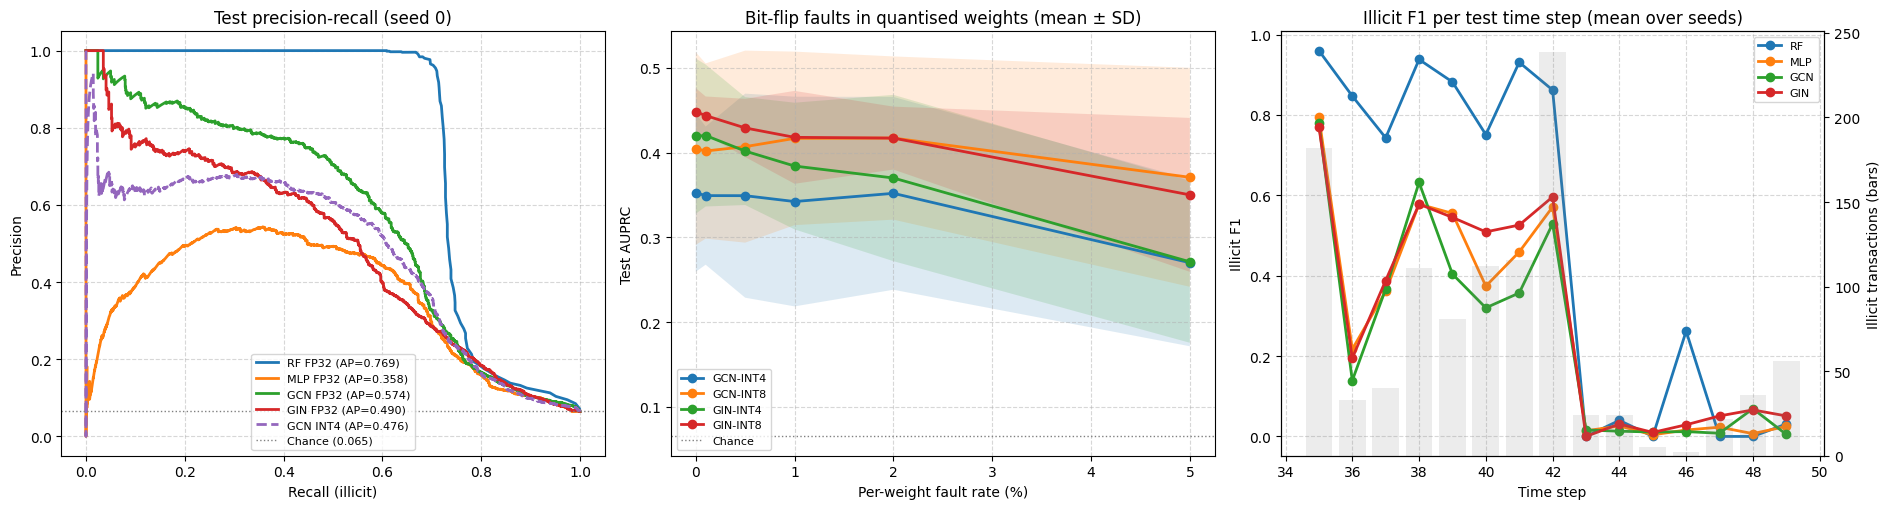

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
yt = Y_ALL[MASK["test"]]

# (a) PR curves, seed 0
for mname in ["RF", "MLP", "GCN", "GIN"]:
    p = PROBS[(mname, 0)][MASK["test"]]
    prec, rec, _ = precision_recall_curve(yt, p)
    axes[0].plot(rec, prec, lw=2, label=f"{mname} FP32 (AP={average_precision_score(yt, p):.3f})")
p4 = predict(quantize_and_inject_faults(MODELS[("GCN", 0)], num_bits=4))[MASK["test"]]
prec, rec, _ = precision_recall_curve(yt, p4)
axes[0].plot(rec, prec, lw=2, ls="--", label=f"GCN INT4 (AP={average_precision_score(yt, p4):.3f})")
axes[0].axhline(yt.mean(), color="grey", ls=":", lw=1, label=f"Chance ({yt.mean():.3f})")
axes[0].set(title="Test precision-recall (seed 0)", xlabel="Recall (illicit)", ylabel="Precision")
axes[0].grid(ls="--", alpha=.5); axes[0].legend(fontsize=8)

# (b) fault sweep, mean ± SD
for cfg, g in df_sweep_runs.groupby("Config"):
    s = g.groupby("Fault rate")["AUPRC"].agg(["mean", "std"]).fillna(0)
    xs = s.index.values * 100
    axes[1].plot(xs, s["mean"], marker="o", lw=2, label=cfg)
    axes[1].fill_between(xs, s["mean"] - s["std"], s["mean"] + s["std"], alpha=.15)
axes[1].axhline(prevalence, color="grey", ls=":", lw=1, label="Chance")
axes[1].set(title="Bit-flip faults in quantised weights (mean ± SD)", xlabel="Per-weight fault rate (%)",
            ylabel="Test AUPRC"); axes[1].grid(ls="--", alpha=.5); axes[1].legend(fontsize=8)

# (c) per-time-step F1
for mname in ["RF", "MLP", "GCN", "GIN"]:
    if mname in df_steps.columns:
        axes[2].plot(df_steps.index, df_steps[mname], marker="o", lw=2, label=mname)
ax2 = axes[2].twinx(); ax2.bar(df_steps.index, df_steps["Illicit"], alpha=.15, color="grey")
ax2.set_ylabel("Illicit transactions (bars)")
axes[2].set(title="Illicit F1 per test time step (mean over seeds)", xlabel="Time step", ylabel="Illicit F1")
axes[2].grid(ls="--", alpha=.5); axes[2].legend(fontsize=8)

plt.tight_layout(); plt.savefig(OUT / "figures.png", dpi=200, bbox_inches="tight"); plt.show()

**Cell 11: Save everything and print the summary**

The tables are written to `results/` as CSV files, together with `figures.png` and `config.json`. In Colab, `results.zip` downloads automatically.



In [11]:
df_splits.to_csv(OUT / "splits.csv", index=False)
df_runs.to_csv(OUT / "runs_fp32_and_baselines.csv", index=False)
df_main.to_csv(OUT / "main_results_mean_sd.csv")
df_paired.to_csv(OUT / "paired_differences.csv", index=False)
df_comp_runs.to_csv(OUT / "compression_runs.csv", index=False)
df_comp.to_csv(OUT / "compression_mean_sd.csv")
df_sweep_runs.to_csv(OUT / "fault_sweep_runs.csv", index=False)
df_sweep.to_csv(OUT / "fault_sweep_mean_sd.csv")
df_steps.to_csv(OUT / "per_time_step_f1.csv")
env = {"torch": torch.__version__, "torch_geometric": torch_geometric.__version__, "sklearn": sklearn.__version__,
       "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu", "data_source": source,
       "runtime_minutes": round((time.time() - T_START) / 60, 1)}
json.dump({"config": CONFIG, "environment": env, "sanity_checks": observed,
           "cross_time_edge_fraction": cross}, open(OUT / "config.json", "w"), indent=2, default=str)

print("=" * 30, "RESULTS SUMMARY", "=" * 30)
print(json.dumps(env))
print("\n[Data]"); print(df_splits.to_string(index=False))
print(f"Cross-time-step edges: {100*cross:.3f}% | sanity: {observed}")
print("\n[Main results, test t35-49, mean ± SD]"); print(df_main.to_string())
print("\n[Paired differences]"); print(df_paired.to_string(index=False))
print("\n[Compression]"); print(df_comp.to_string())
print("\n[Fault sweep AUPRC]"); print(df_sweep.to_string())
print("\n[Fault sweep retained AUPRC]"); print(df_retained.to_string())
print("\n[Fault sweep worst run]"); print(df_worst.to_string())
print("\n[Per-time-step F1]"); print(df_steps.to_string())
print("=" * 77)

import shutil
shutil.make_archive("results", "zip", OUT)
try:
    from google.colab import files
    files.download("results.zip")
except Exception:
    print("results.zip saved in the working directory.")

============================== RESULTS SUMMARY ==============================
{"torch": "2.14.1+cu130", "torch_geometric": "2.8.1", "sklearn": "1.6.1", "device": "NVIDIA L4", "data_source": "Kaggle (kagglehub)", "runtime_minutes": 3.1}

[Data]
        Split  Labelled  Illicit  Illicit %
Train (t1-28)     25207     2542      10.08
 Val (t29-34)      4687      920      19.63
Test (t35-49)     16670     1083       6.50
Cross-time-step edges: 0.000% | sanity: {'nodes': 203769, 'directed edges': 234355, 'labelled nodes': 46564, 'illicit': 4545, 'features': 165}

[Main results, test t35-49, mean ± SD]
        n runs            AUROC            AUPRC           F1@0.5       F1@val-thr     Prec@val-thr      Rec@val-thr              ECE            Brier
Model                                                                                                                                                 
LogReg       1           0.8766           0.2650           0.3013           0.2796           0.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


- **Limitations:**
  - Single dataset; one temporal split.
  - The illicit share differs between validation and test.
  - Weber et al. (2019) reported that models fail on the time steps after the dark-market shutdown.
  - Hyperparameters were not tuned per model.
  - Five seeds is a small sample.